In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import uproot
import pandas as pd
import subprocess

from torch.utils.data import Dataset, DataLoader, random_split

In [2]:
# returns the serial number of the gpu with most free memory
def get_free_gpu():
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
        capture_output=True, text=True
    )
    free_mem = [int(x) for x in result.stdout.strip().split("\n")]
    best_gpu = free_mem.index(max(free_mem))
    print(f"Selected GPU {best_gpu} ({free_mem[best_gpu]} MiB free)")
    return best_gpu

In [3]:
# If running on Apple Silicon or CUDA is available, use the GPU.

# if torch.backends.mps.is_available():
#     device = "mps"
# elif torch.cuda.is_available():
#     device = "cuda"
#     current_device_number = get_free_gpu()
#     torch.cuda.set_device(current_device_number)
# else:
#     device = "cpu"

device = "cpu"
# We are only doing analysis in this notebook so cpu is enough

### Data loading and preprocessing for training
Import Data

In [4]:
# Get the absolute path of the directory where the notebook is located
cwd = os.getcwd()
print("Current working directory", cwd)
data_folder = os.path.dirname(os.path.dirname(cwd))
data_folder = os.path.join(data_folder, '0_test_exercise')
file_name = os.path.join(data_folder, 'ntuple.18192176.0.root')

with uproot.open(file_name) as file:
    key = file.keys()[0]
    tree = uproot.open(f"{file_name}:" + key)
    print("File opened successfully!")
    print(f"Available classes: {file.classnames()}")
    print(f"Imported Class: {key}")
    print(f"Tree information: {tree}")

Current working directory /scratch/users/yinya/1.0_toy_model/1.0_toy_model


File opened successfully!
Available classes: {'susy;1': 'TTree'}
Imported Class: susy;1
Tree information: <TTree 'susy' (1536 branches) at 0x7f3410771e10>


Select Branches

In [5]:
theory_param = [branch for branch in tree.keys() if branch.startswith('IN')]
# measure_param = [branch for branch in tree.keys() if branch.startswith('SP')]

Build Trees and remove unnecessary branches (branch with constant values)

In [6]:
def split_constant_nonconstant_columns(df: pd.DataFrame, return_names = False):
    """
    Splits a DataFrame into:
    - constant_df: columns where all values are identical
    - nonconstant_df: columns where at least one value differs
    """
    
    # A column is constant if it has exactly one unique value
    constant_columns = df.nunique(dropna=False) == 1
    
    constant_df = df.loc[:, constant_columns]
    nonconstant_df = df.loc[:, ~constant_columns]
    
    if return_names:
        return constant_df.columns, nonconstant_df.columns
    else:
        return constant_df, nonconstant_df

In [7]:
theory_tree = tree.arrays(theory_param, library='pd')
_, theory_param_nonconst = split_constant_nonconstant_columns(theory_tree, return_names=True)
del theory_tree

# measure_tree = tree.arrays(measure_param, library='pd')
# _, measure_param_nonconst = split_constant_nonconstant_columns(measure_tree, return_names=True)
# del measure_tree

In [8]:
parameters = tree.arrays(theory_param_nonconst, library='pd').astype(np.float32)
mo_omega = tree['MO_Omega'].array(library="np").astype(np.float32)
mo_omega = mo_omega[:, None] #This is to prevent tensor dimension conflict when calculating loss

In [9]:
mask = (mo_omega != -1).flatten()
parameters = parameters[mask]
mo_omega = mo_omega[mask]

To make training easy for the normalizing flow, we standardize the parameters:

In [10]:
parameters_mean = np.mean(parameters, axis=0)
parameters_std = np.std(parameters, axis=0)

parameters_standardized = (parameters - parameters_mean) / parameters_std

In [11]:
type(mo_omega[0, 0])

numpy.float32

In [12]:
type(parameters_standardized.iloc[0]['IN_M_1'])

numpy.float32

In [13]:
parameters_standardized.shape

(9607, 12)

In [14]:
class pMSSM_Dataset(Dataset):
    def __init__(self, parameters, observables):
        self.parameters = parameters
        self.observables = observables

    def __len__(self):
        return len(self.parameters)

    def __getitem__(self, idx):
        params = self.parameters.iloc[idx]
        signal = self.observables[idx]
        
        # Add unit normal noise to the signal
        # noise = np.random.normal(size = signal.shape).astype(np.float32)
        # data = signal + noise
        data = signal
        if device == "mps":
            return torch.tensor(data, dtype=torch.float64, device=device), torch.tensor(params,  dtype=torch.float64, device=device)
        else:
            return torch.tensor(data, device=device), torch.tensor(params, device=device)
    
mo_omega_dataset = pMSSM_Dataset(parameters_standardized, mo_omega)

Visualize the data $d$ from an arbitrary sample of the `pMSSM_dataset`.

In [15]:
# Get first sample
signal, params = mo_omega_dataset[0]
signal = signal.cpu()  # Careful to put data back onto CPU.
print(signal)
print(params)

tensor([86.7000])
tensor([ 0.5485,  1.1125, -0.5387,  1.2056, -0.5841,  0.3705,  1.2141, -1.0644,
         0.1646,  0.4739,  0.3704, -0.2141])


/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


### Split data into train and test dataset
Determine the number of training and test samples from a `train_fraction` and use the function `random_split()` to separate the data into a training and test dataset. Afterwards define the training and test dataloaders.

In [16]:
num_samples = len(mo_omega_dataset)
train_fraction = 0.8
num_train = int(round(train_fraction * num_samples))
num_test = num_samples - num_train
# generator1 = torch.Generator().manual_seed(42)
# train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test], generator=generator1)
train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test])
#In the current version (01.06.2026) there is a problem that the RNG seed for random split was not specified for toy models 1-5,
# which means we cannot recover the same train test split for the models, and we might be using data for evaluation that was used in training sample.

### Conditional Normalizing Flow
We use the `glasflow` library. It is a wrapper for [`nflows`](https://github.com/bayesiains/nflows), which implements different flow types (e.g. autoregressive flows and coupling flows) and transforms (e.g. rational-quadratic splines).


In [17]:

from glasflow.nflows import transforms, distributions, flows
import glasflow.nflows as nflows
import glasflow.nflows.nn.nets as nflows_nets

device = 'cpu'  # For some reason, "mps" does not work here.

THe Code is adapted from examples in the [neural spline flow repository](https://github.com/bayesiains/nsf).

First, we define a function that creates the basic MAF or RQS-coupling transform:

In [18]:
def create_base_transform(
    i: int,
    param_dim: int,
    context_dim: int = None,
    hidden_dim: int = 512,
    num_transform_blocks: int = 2,
    batch_norm: bool = False,
    base_transform_type: str = "rq-coupling",
):
    
    activation_fn = torch.nn.ELU()

    if base_transform_type == "maf":
        return transforms.MaskedAffineAutoregressiveTransform(
            param_dim,
            hidden_features=hidden_dim,
            context_features=context_dim,
            num_blocks=num_transform_blocks,
            activation=activation_fn,
            use_batch_norm=batch_norm,
        )
    elif base_transform_type == "rq-coupling":
        if param_dim == 1:
            mask = torch.tensor([1], dtype=torch.uint8)
        else:
            mask = nflows.utils.create_alternating_binary_mask(
                param_dim, even=(i % 2 == 0)
            )
        return transforms.PiecewiseRationalQuadraticCouplingTransform(
            mask=mask,
            transform_net_create_fn=(
                lambda in_features, out_features: nflows_nets.ResidualNet(
                    in_features=in_features,
                    out_features=out_features,
                    hidden_features=hidden_dim,
                    context_features=context_dim,
                    num_blocks=num_transform_blocks,
                    activation=activation_fn,
                    use_batch_norm=batch_norm,
                )
            ),
            num_bins=8,
            tails="linear",
            tail_bound=1.0,
            apply_unconditional_transform=False,
        )

    else:
        raise ValueError

Next, we need to define a transform the randomly permutes the dimensions to ensure that all dimensions interact sufficiently with each other:

In [19]:
def create_linear_transform(param_dim: int):
    return transforms.CompositeTransform(
        [
            transforms.RandomPermutation(features=param_dim),
            transforms.LULinear(param_dim, identity_init=True),
        ]
    )

Finally, we can define the `create_transform` function which composes a list of `num_flow_steps` transforms where each transform consists of a linear transform (to permute dimensions) and a base transform (MAF or RQ-coupling).
We start and finish the transforms with a linear transform that ensures that the flow outputs samples that have the correct dimensionality (`param_dim`).

In [20]:
def create_transform(
    num_flow_steps: int, 
    param_dim: int, 
    context_dim: int, 
    base_transform_kwargs: dict
):
    return transforms.CompositeTransform(
        [
            transforms.CompositeTransform(
                [
                    create_linear_transform(param_dim),
                    create_base_transform(
                        i, param_dim, context_dim=context_dim, **base_transform_kwargs
                    ),
                ]
            )
            for i in range(num_flow_steps)
        ]
        + [create_linear_transform(param_dim)]
    )

The entire flow model consists of a standard normal base distribution, followed by the flow transform.

In [21]:
transform = create_transform(num_flow_steps = 10,
                             param_dim = np.shape(parameters)[-1],
                             context_dim = np.shape(mo_omega)[-1], #np.shape(data) instead of data.shape to avoid error by one-dim array
                             base_transform_kwargs = {"base_transform_type": "rq-coupling"})

base_distribution = distributions.StandardNormal(shape=[parameters.shape[-1]])

model = flows.Flow(transform, base_distribution)
model.to(device)

Flow(
  (_transform): CompositeTransform(
    (_transforms): ModuleList(
      (0-9): 10 x CompositeTransform(
        (_transforms): ModuleList(
          (0): CompositeTransform(
            (_transforms): ModuleList(
              (0): RandomPermutation()
              (1): LULinear()
            )
          )
          (1): PiecewiseRationalQuadraticCouplingTransform(
            (transform_net): ResidualNet(
              (initial_layer): Linear(in_features=7, out_features=512, bias=True)
              (blocks): ModuleList(
                (0-1): 2 x ResidualBlock(
                  (activation): ELU(alpha=1.0)
                  (context_layer): Linear(in_features=1, out_features=512, bias=True)
                  (linear_layers): ModuleList(
                    (0-1): 2 x Linear(in_features=512, out_features=512, bias=True)
                  )
                  (dropout): Dropout(p=0.0, inplace=False)
                )
              )
              (final_layer): Linear(in_feature

### Load Weights into the Model

In [22]:
id_training = 5
weights_path = f"../checkpoints/training_{id_training}.pt"
# weights_path = f"../checkpoints/training_{id_training}_epoch_1000.pt"
model.load_state_dict(torch.load(weights_path))

/tmp/ipykernel_3536979/1839186935.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights_path))


<All keys matched successfully>

### Visualize posteriors

In [25]:
model.eval()

Flow(
  (_transform): CompositeTransform(
    (_transforms): ModuleList(
      (0-9): 10 x CompositeTransform(
        (_transforms): ModuleList(
          (0): CompositeTransform(
            (_transforms): ModuleList(
              (0): RandomPermutation()
              (1): LULinear()
            )
          )
          (1): PiecewiseRationalQuadraticCouplingTransform(
            (transform_net): ResidualNet(
              (initial_layer): Linear(in_features=7, out_features=512, bias=True)
              (blocks): ModuleList(
                (0-1): 2 x ResidualBlock(
                  (activation): ELU(alpha=1.0)
                  (context_layer): Linear(in_features=1, out_features=512, bias=True)
                  (linear_layers): ModuleList(
                    (0-1): 2 x Linear(in_features=512, out_features=512, bias=True)
                  )
                  (dropout): Dropout(p=0.0, inplace=False)
                )
              )
              (final_layer): Linear(in_feature

In [23]:
# test_dataset[0]
# import torch
# from torch.utils.data import DataLoader

def find_closest(dataset, target: float):
    """
    Returns the dataset item whose first tensor entry is closest to `target`.
    
    Args:
        dataset: A PyTorch Dataset where each item is (scalar_tensor, feature_tensor)
        target:  The float value to search for
    
    Returns:
        (best_item, best_idx, best_diff) – the matching item, its index, and the absolute difference
    """
    target_t = torch.tensor(target)
    best_idx  = None
    best_diff = float("inf")

    for idx in range(len(dataset)):
        item = dataset[idx]
        diff = (item[0] - target_t).abs().item()
        if diff < best_diff:
            best_diff = diff
            best_idx  = idx

    return dataset[best_idx], best_idx, best_diff

In [35]:
test_dataset[2]

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


(tensor([0.0089]),
 tensor([ 1.0065, -0.5071, -1.0751,  0.4430, -0.6126,  0.8564,  1.2527, -0.4708,
         -1.0928, -1.3255,  0.6493, -0.3676]))

In [31]:
dataset_cl, idx_cl, diff_cl = find_closest(test_dataset, 10)
dataset_cl

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


(tensor([10.]),
 tensor([-0.6546,  0.7801, -1.4758,  0.4952, -0.1183,  1.5442, -0.8791, -0.1063,
          1.2031, -1.0123,  0.2811, -1.5030]))

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)


/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  axes[k1, k1].axvline(xs[k1], **kwargs)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:849: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with D

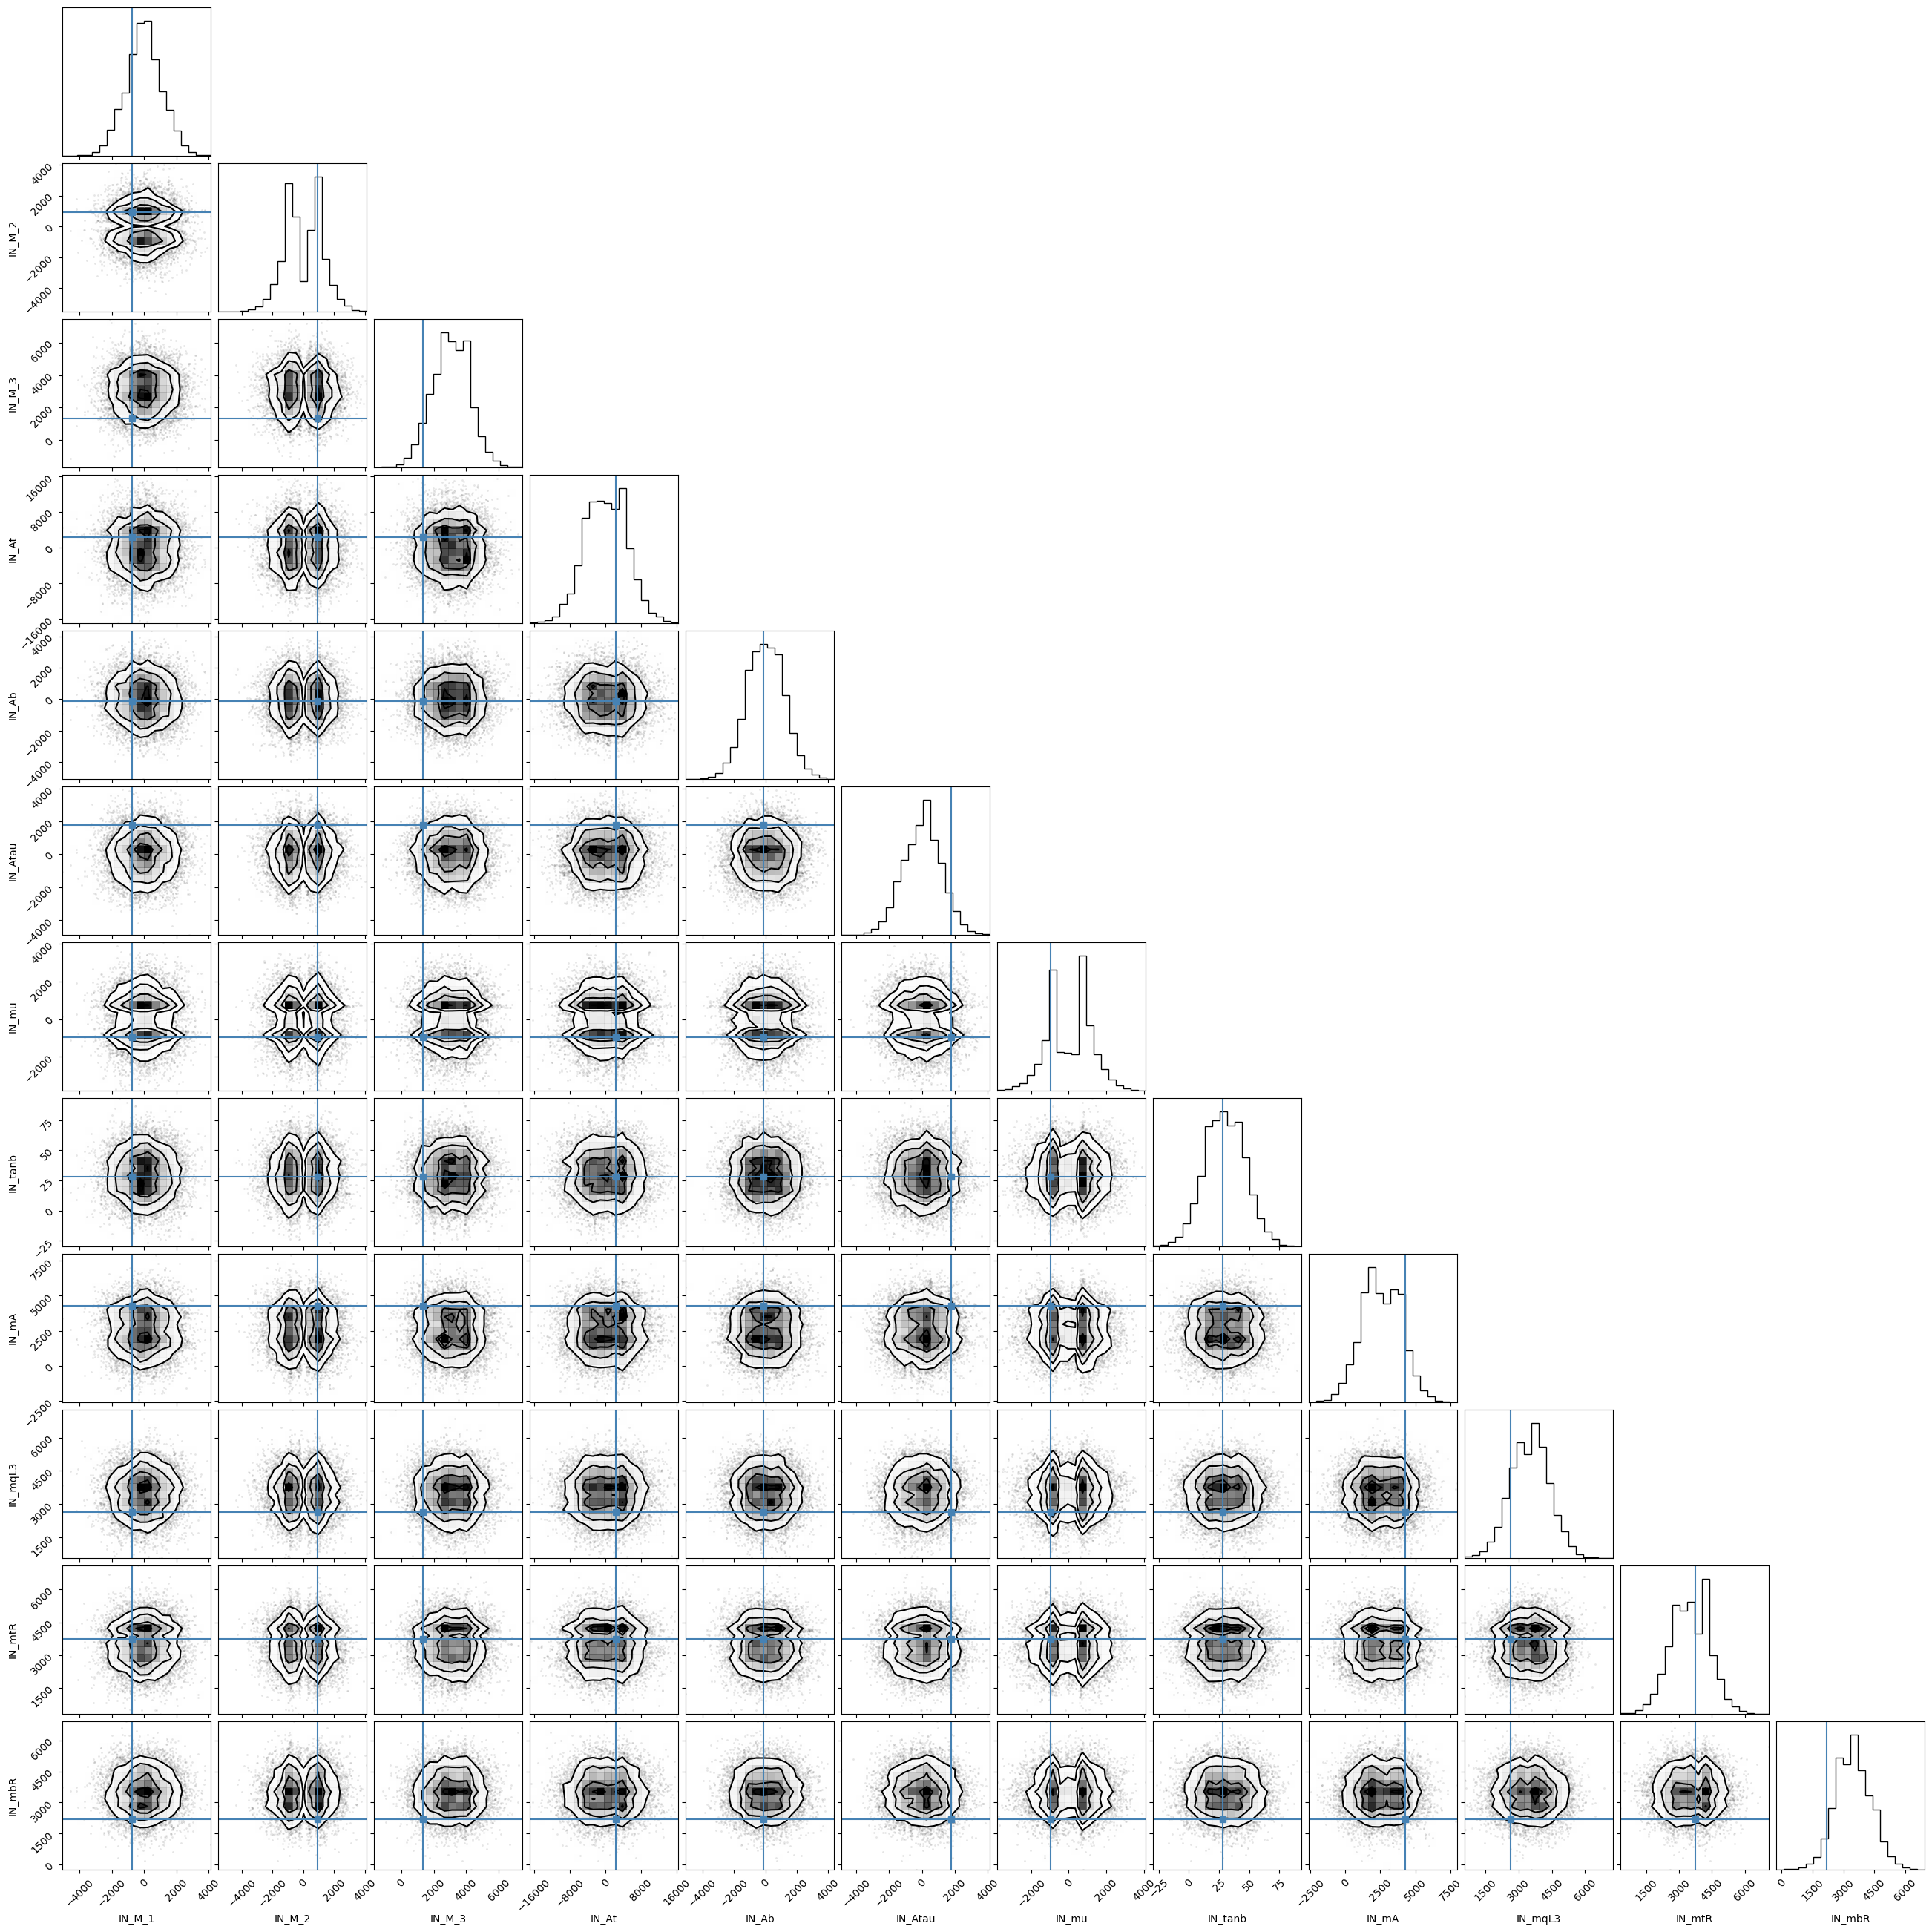

In [32]:
with torch.no_grad():

    test_x, test_y = test_dataset[idx_cl]

    # Sample the posterior
    test_x = test_x.expand(10000, *test_x.shape)
    pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()

    # Undo the standardization
    pred_samples = parameters_std.to_numpy() * pred_samples + parameters_mean.to_numpy()
    truth = parameters_std * test_y.cpu().numpy() + parameters_mean

    # Plot
    corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
    plt.show()

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

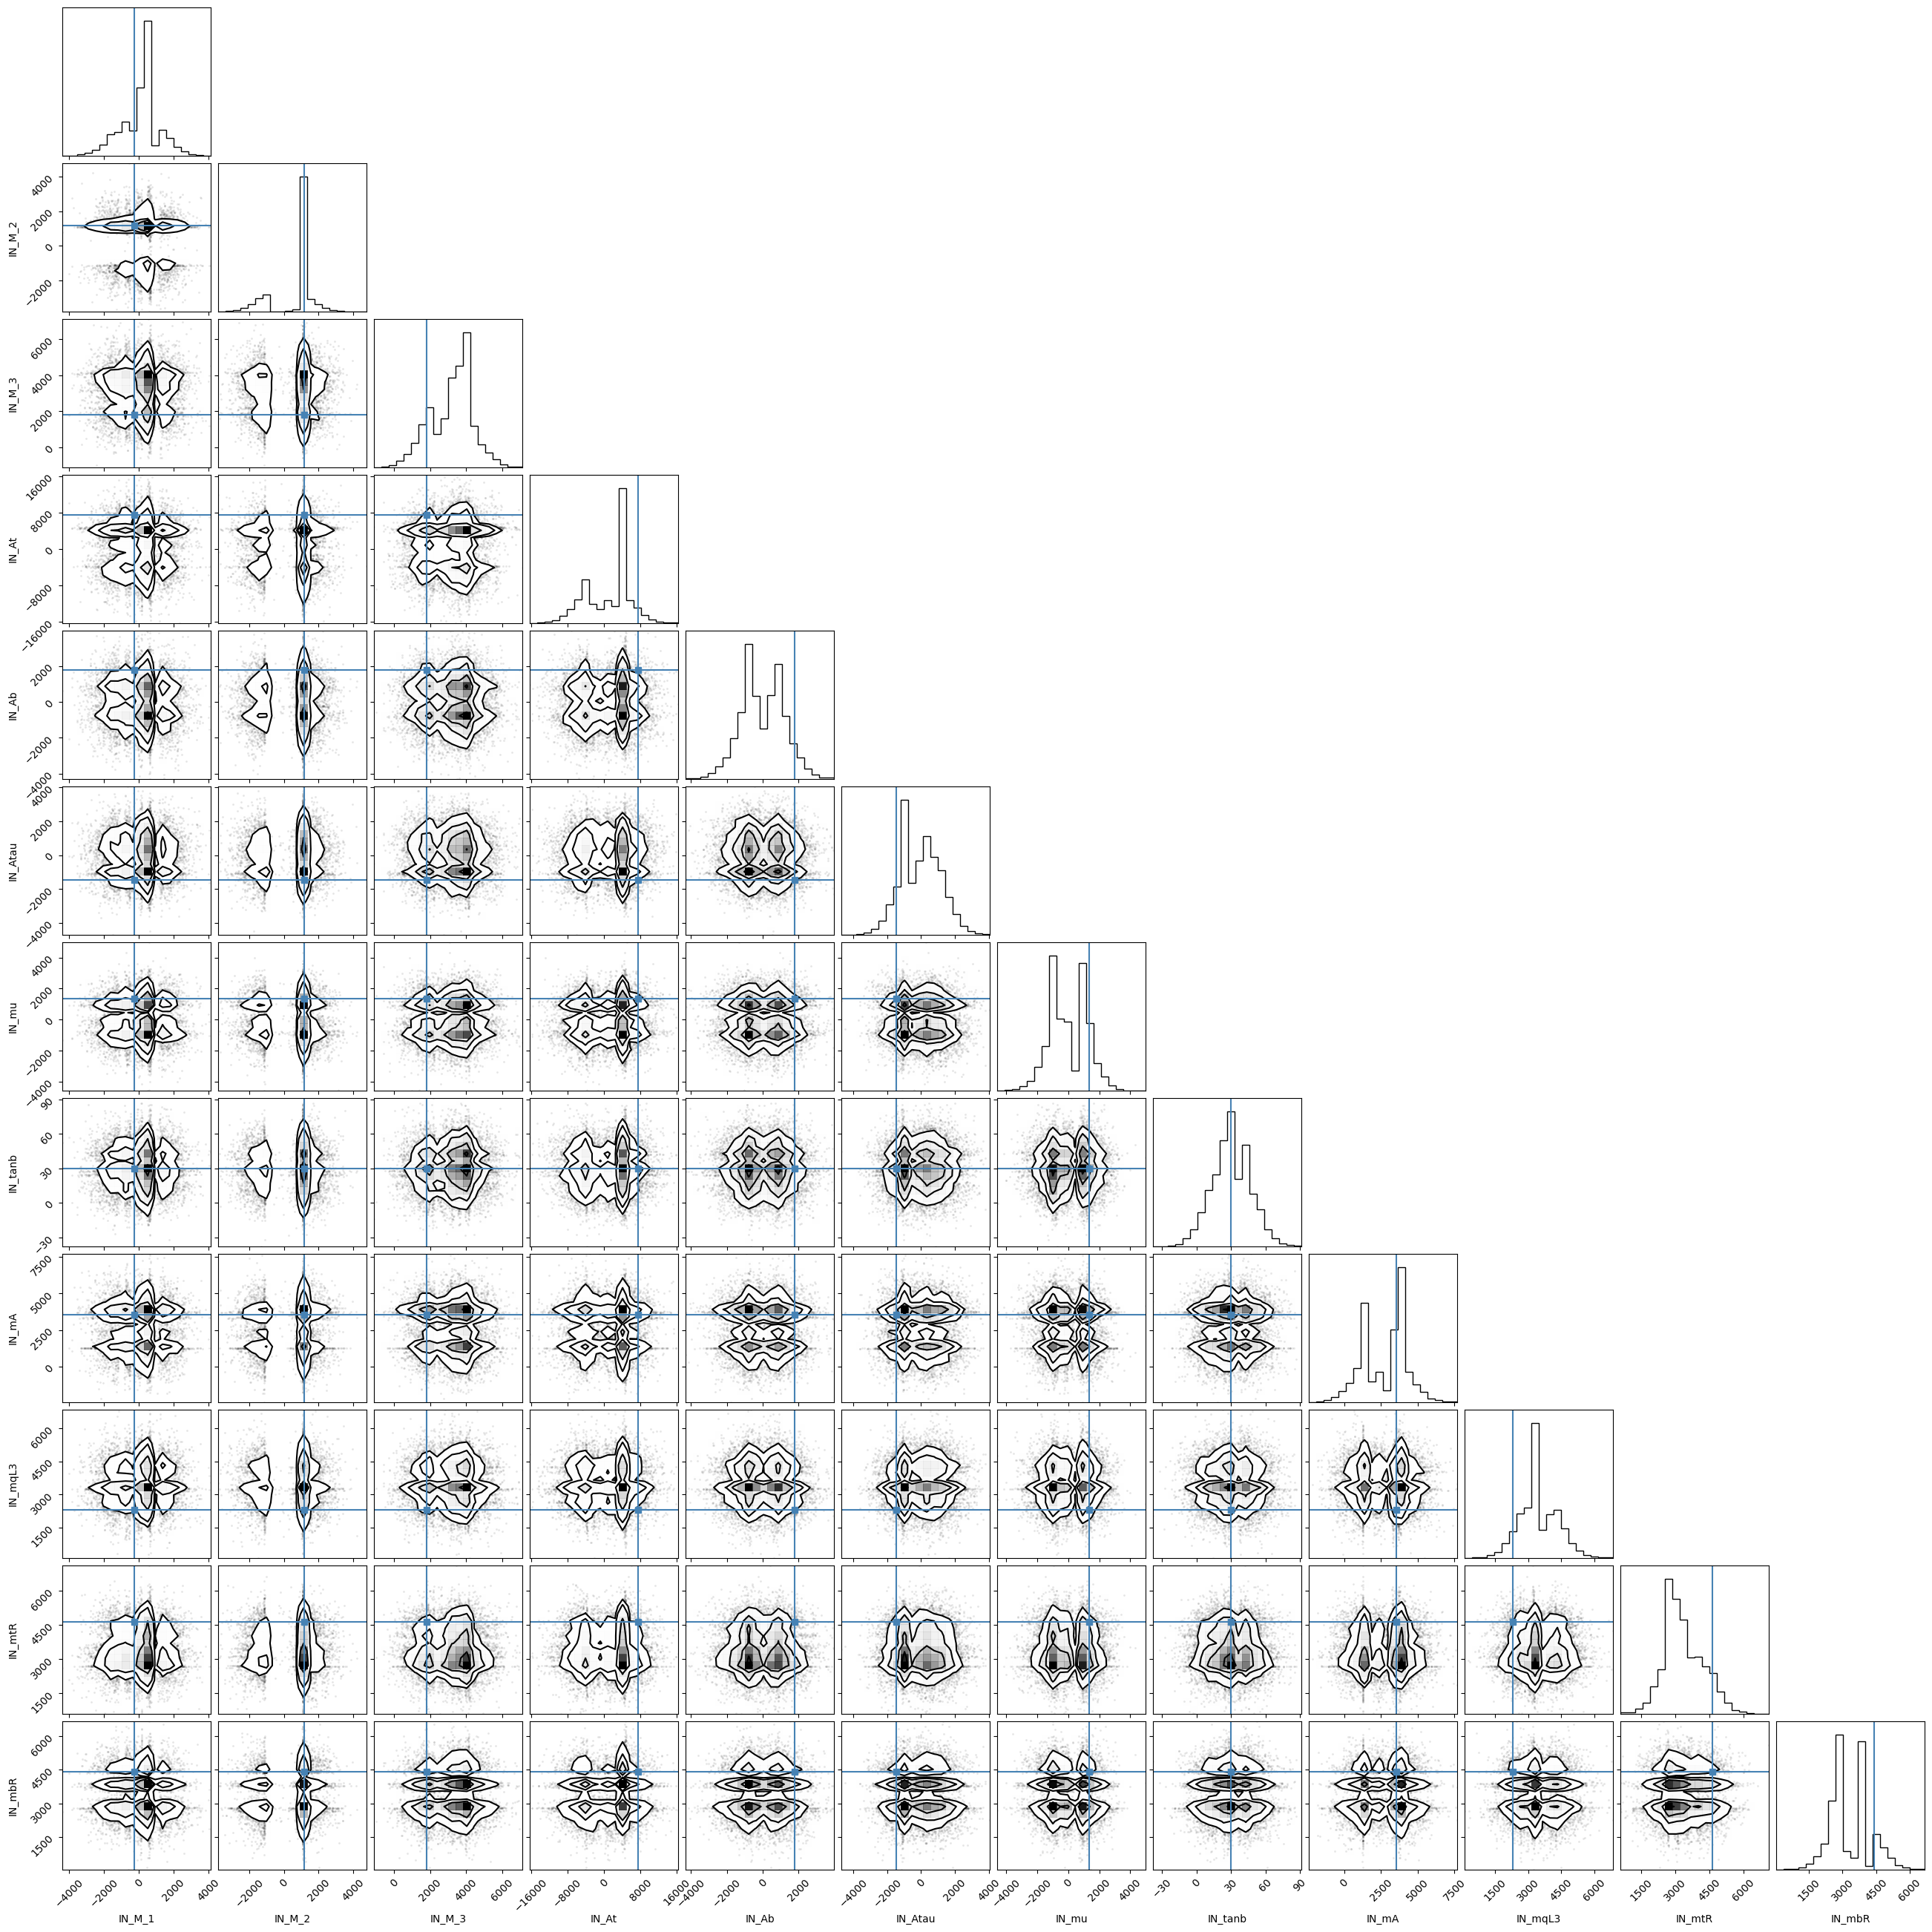

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

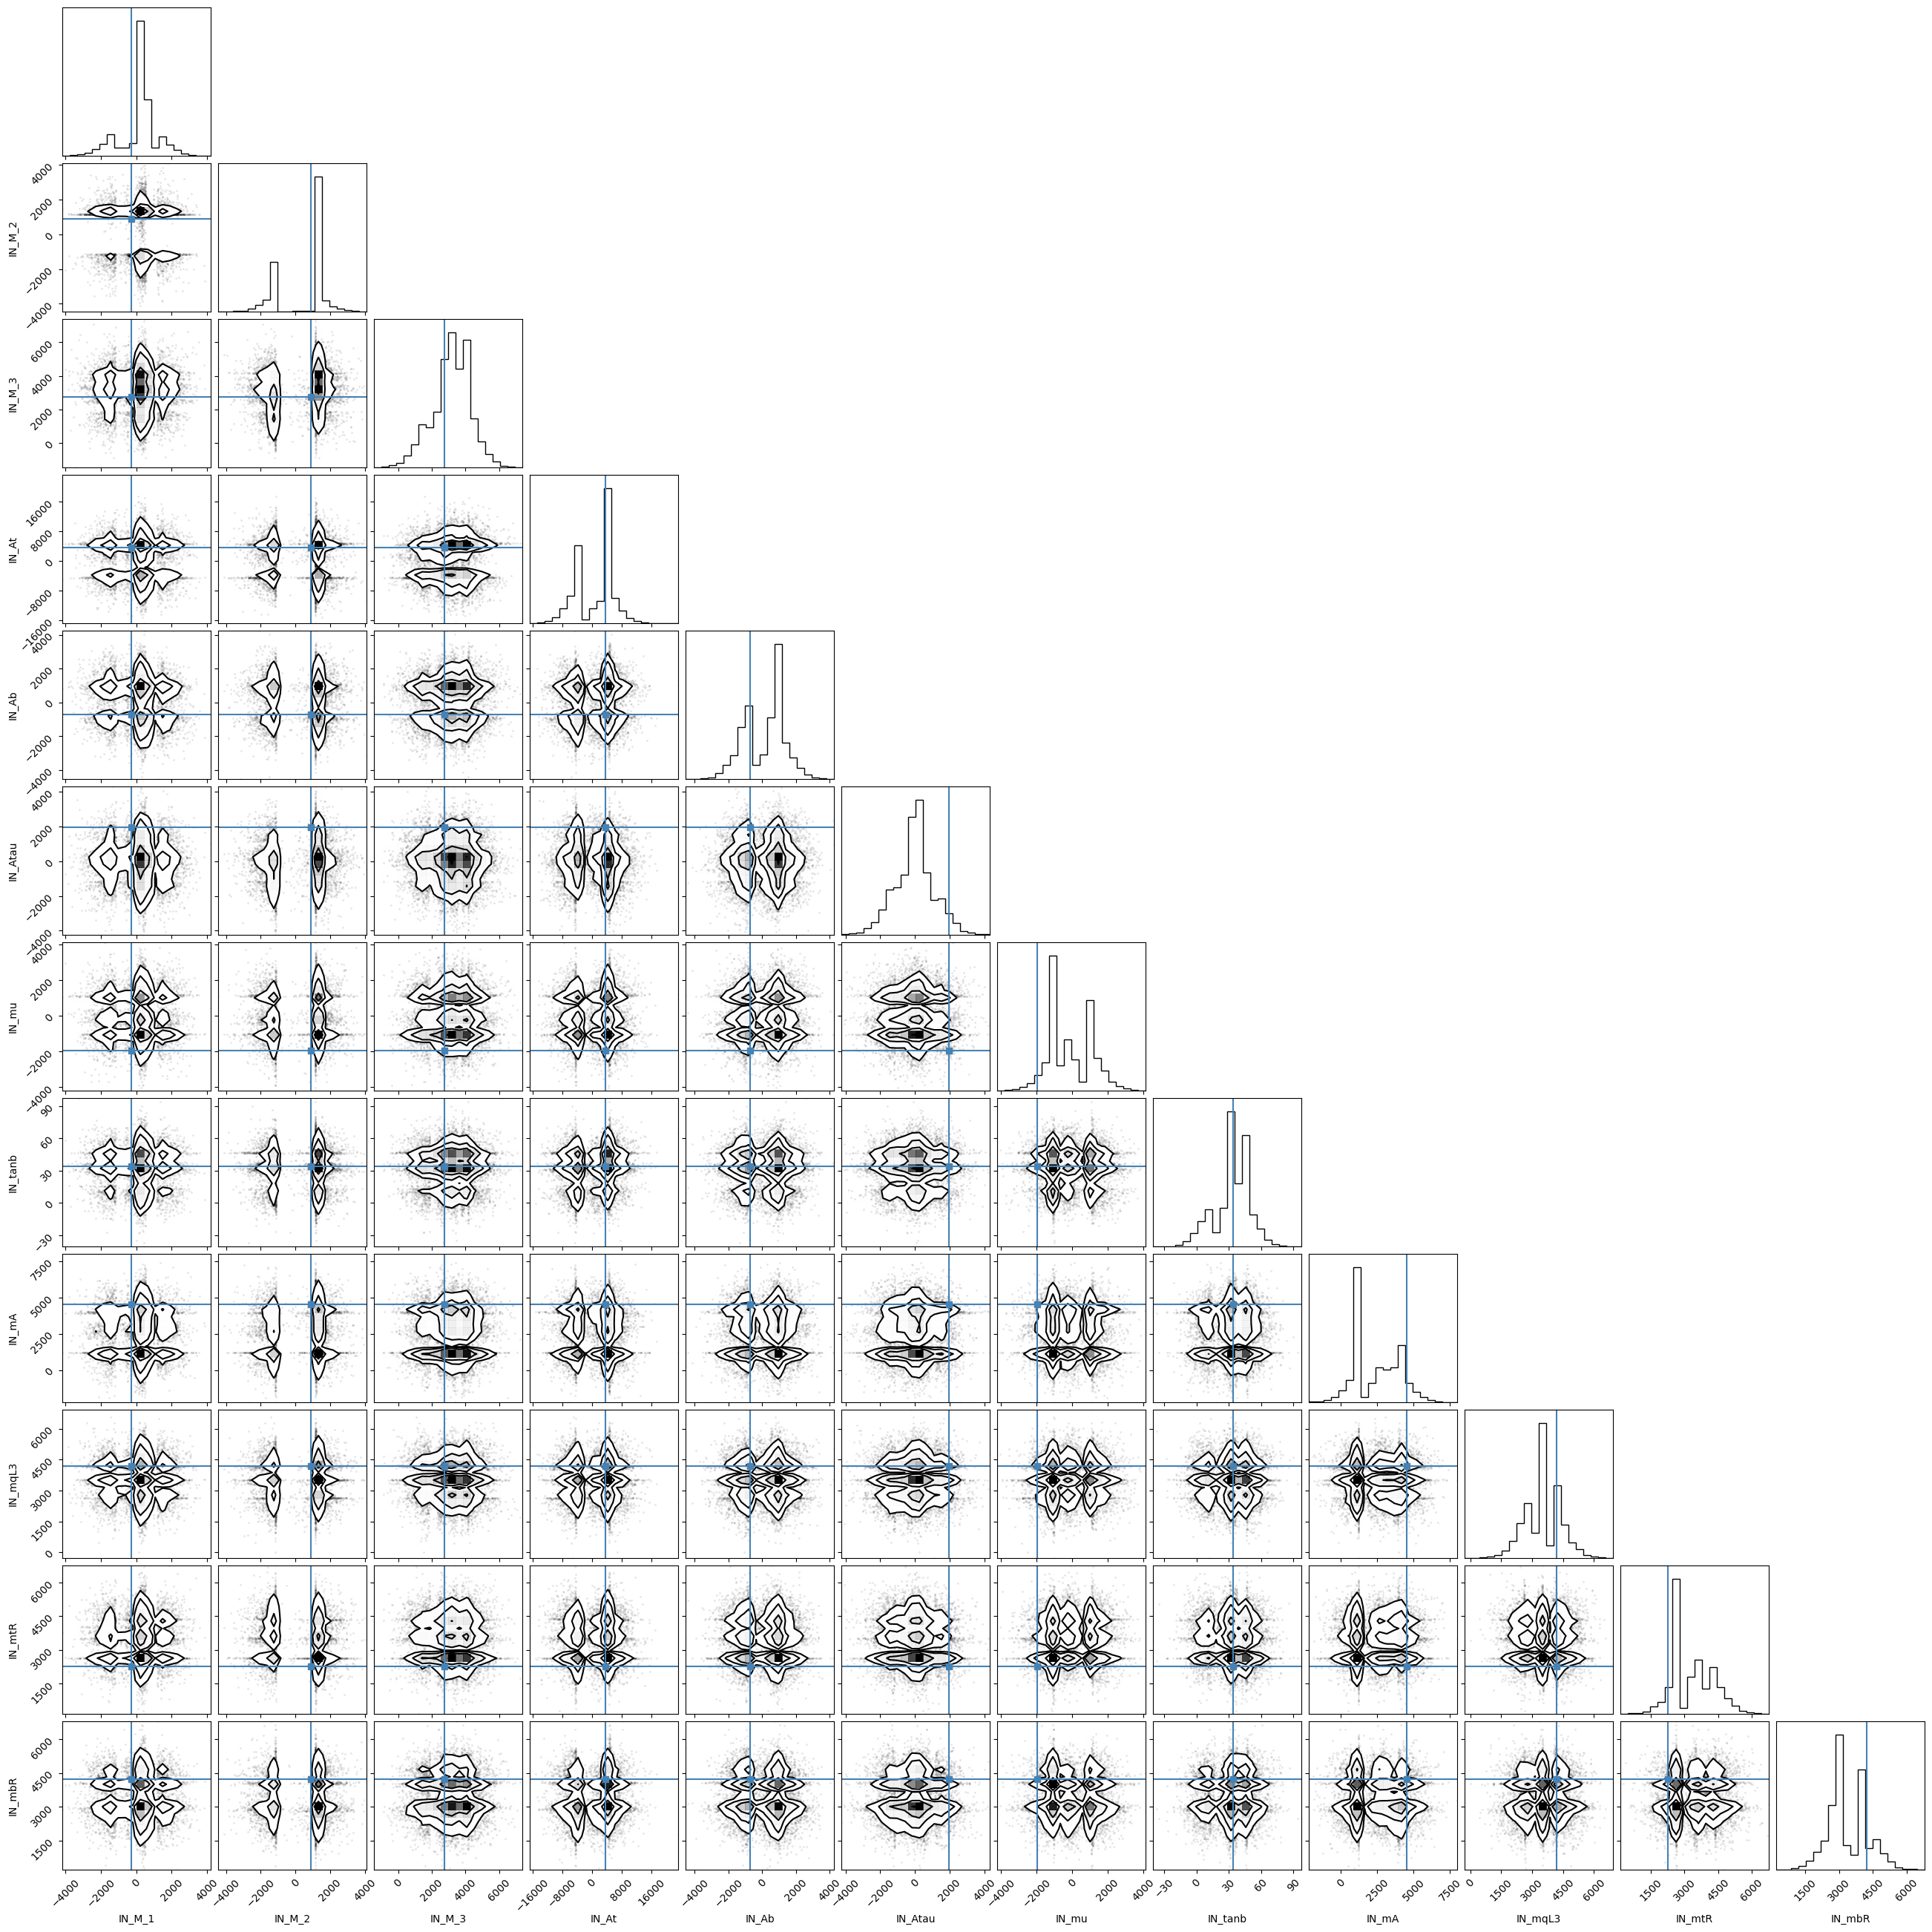

/tmp/ipykernel_3536979/394356444.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return torch.tensor(data, device=device), torch.tensor(params, device=device)
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:846: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if xs[k1] is not None:
/scratch/users/yinya/1.0_toy_model/.pixi/envs/default/lib/python3.11/site-packages/corner/core.py:847: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To a

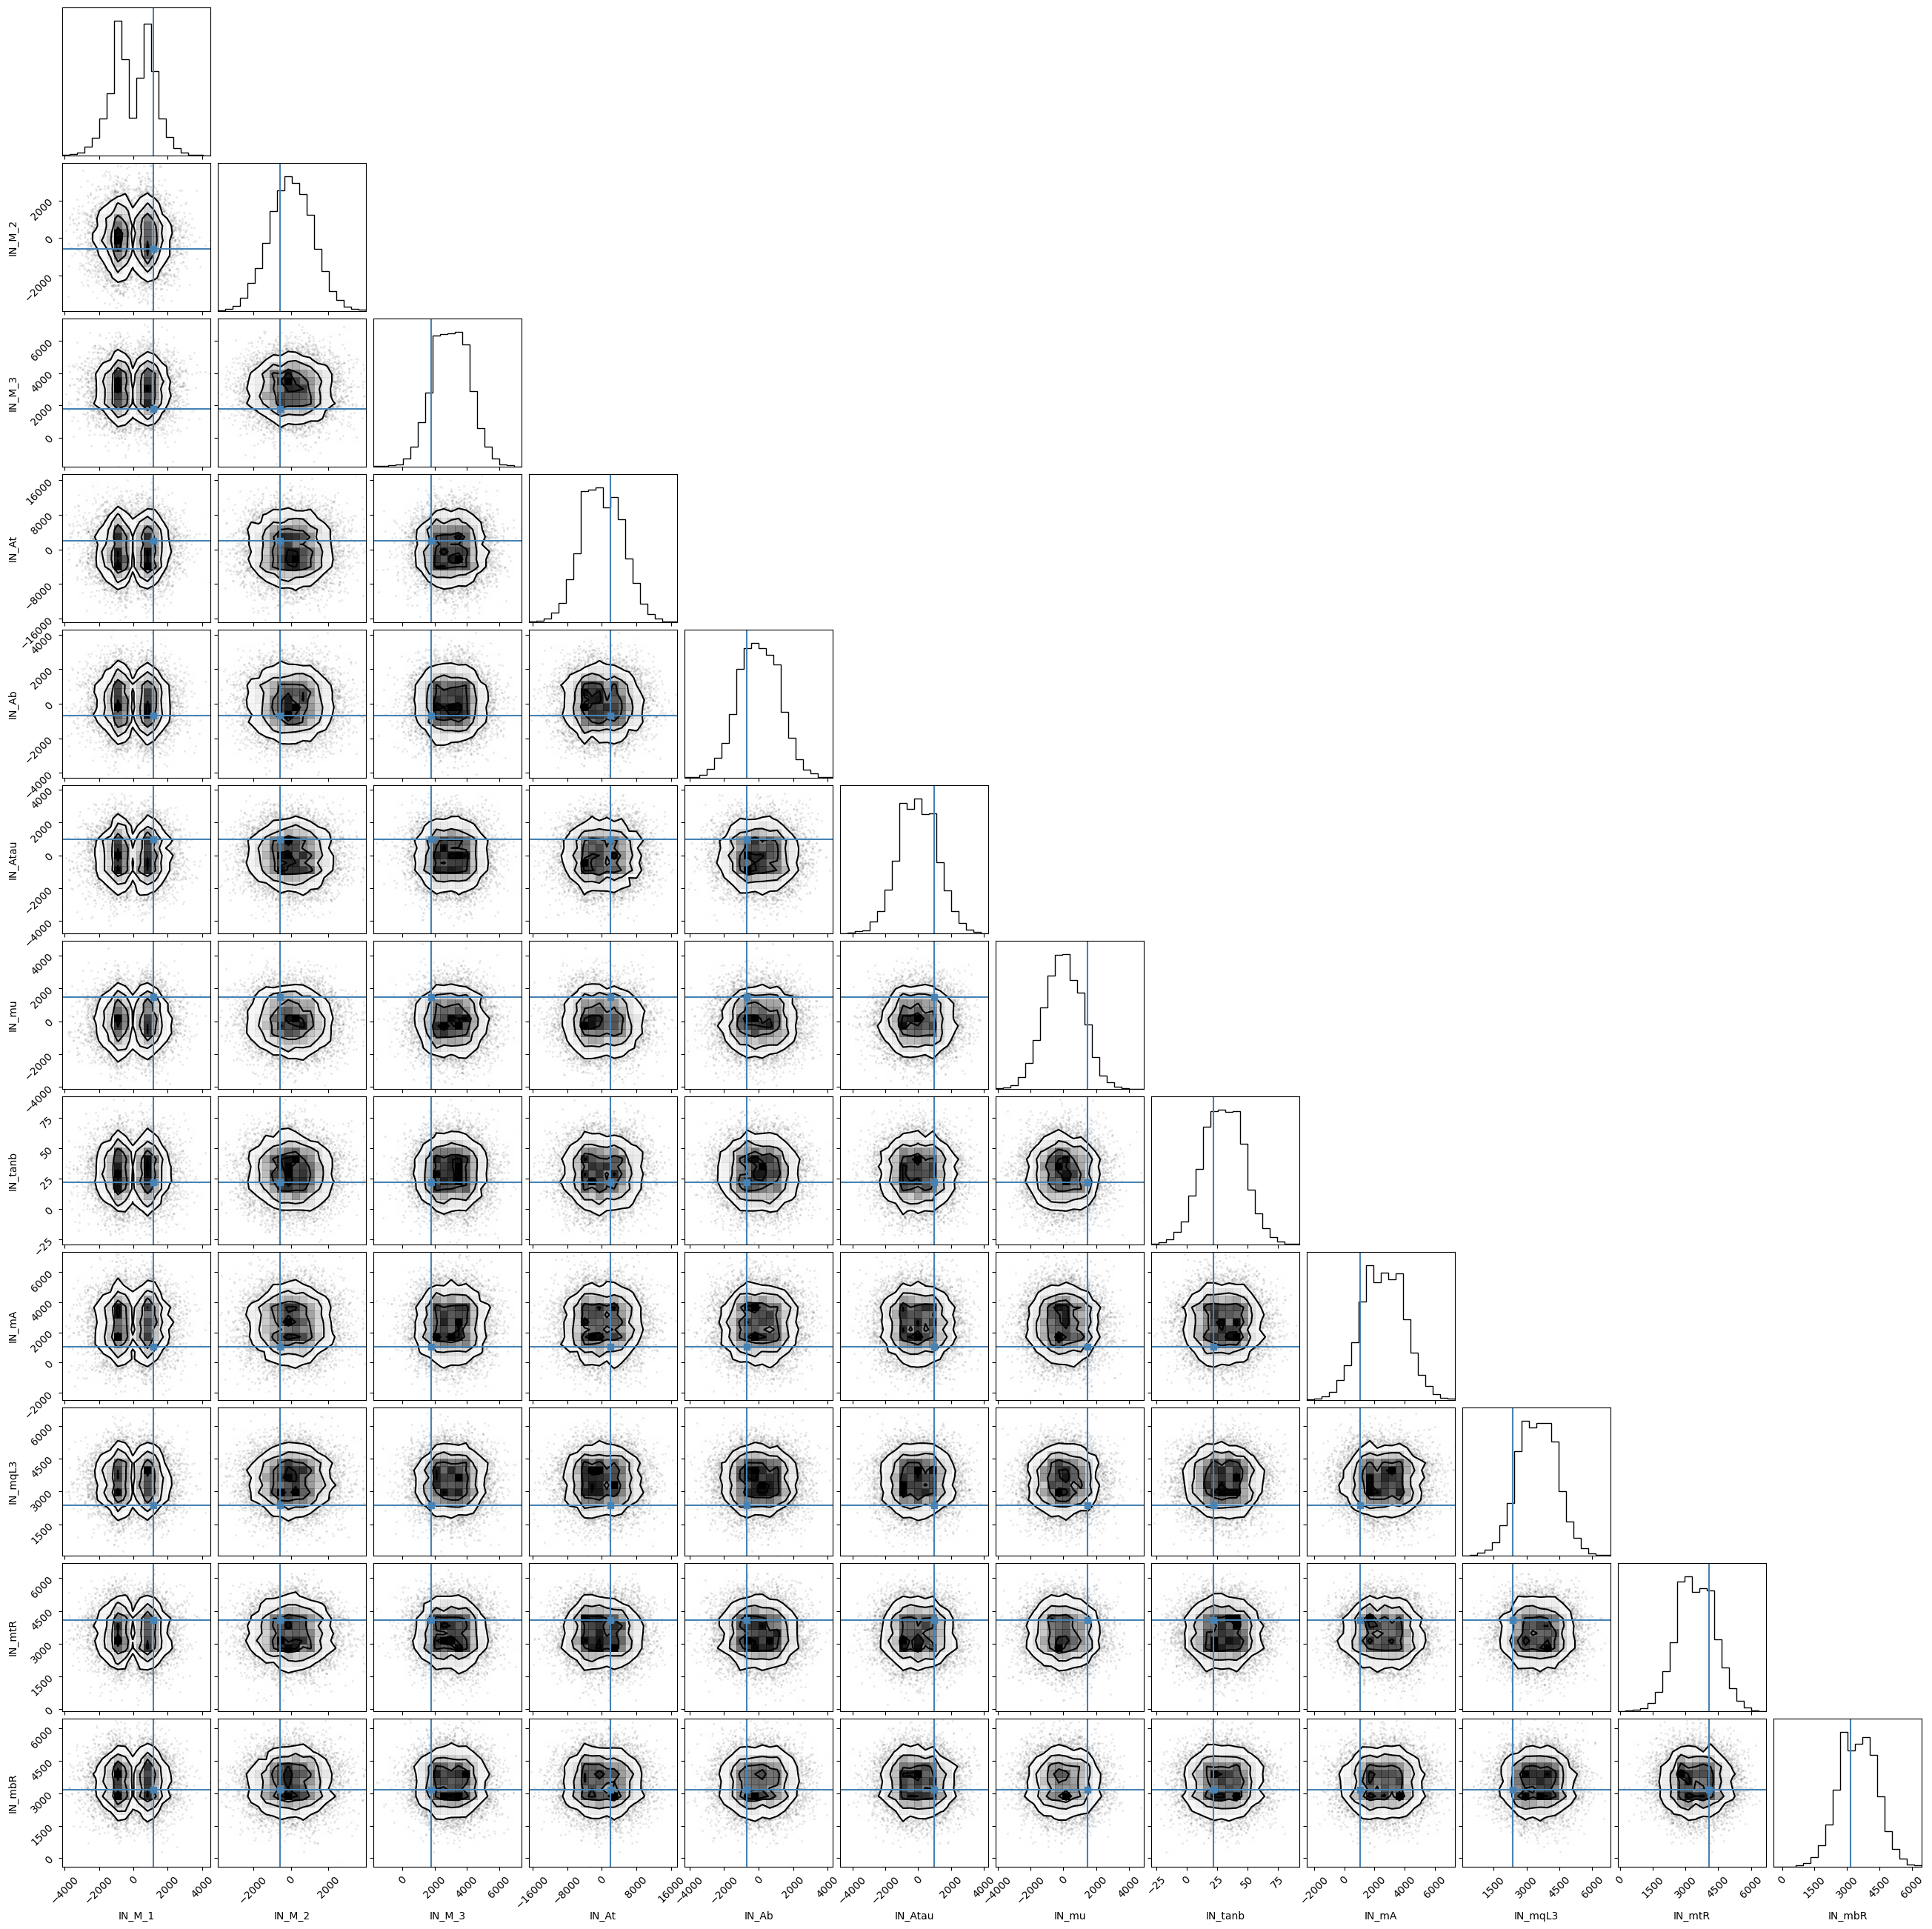

In [36]:
num_posteriors = 3
num_eval_samples = 10_000

model.eval()

for n in range(num_posteriors):

    with torch.no_grad():
    
        test_x, test_y = test_dataset[n]
    
        # Sample the posterior
        test_x = test_x.expand(num_eval_samples, *test_x.shape)
        pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()
    
        # Undo the standardization
        pred_samples = parameters_std.to_numpy() * pred_samples + parameters_mean.to_numpy()
        truth = parameters_std * test_y.cpu().numpy() + parameters_mean
    
        # Plot
        corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
        plt.show()